# Lista 2: Inteligência Artificial (UFAL)
## Questão 10: Planejamento de rotas para entregas urbanas

**Dupla:**
- Bruno Gomes de Barros Filho, matrícula 21111360
- Antônio Rodrigo Lima de Andrade Tenório, matrícula 23210707

**Disciplina:** ECOM031: Inteligência Artificial
**Professor:** Evandro de Barros Costa
**Período:** 2026.2

---

### Enunciado (Q10)
> Uma empresa de entregas utiliza um agente inteligente para determinar a rota de menor tempo
> entre um centro de distribuição A e um destino I. O mapa é um grafo não direcionado, com nove
> localidades e custos de deslocamento em minutos.
>
> 1. Formule o problema (estados, estado inicial, ações, transição, teste de objetivo, custo).
> 2. Execute Busca em Profundidade (BFS) e Busca de Custo Uniforme (UCS): ordem de expansão, rota e custo.
> 3. Execute A* mostrando g(n), h(n) e f(n) = g(n) + h(n).
> 4. Compare as buscas quanto a custo, nós expandidos, completude e otimalidade.
> 5. Obrigue o entregador a visitar D e F antes de I, em qualquer ordem: nova representação de estados e rota de menor custo.

O enunciado escreve "Busca em Profundidade (BFS)". Profundidade é DFS; BFS é busca em largura.
Como não dá para saber qual das duas foi pedida, este notebook executa as duas.

O código das buscas está em `q10_problema.py` (dados e formulação) e `q10_algoritmos.py`
(BFS, DFS, UCS, A*, trace e verificação de heurísticas). As tabelas abaixo são geradas por esse código.

In [1]:
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import Markdown, display

from q10_problema import (GRAFO, H_ENUNCIADO, TRECHOS, ProblemaRota, ProblemaRotaDF,
                          criar_h_paradas, dijkstra, h_enunciado, h_nula)
from q10_algoritmos import (a_estrela, bfs, dfs, estados_alcancaveis, resumo,
                            tabela_trace, ucs, verificar_heuristica)

FIG = Path('figures')
FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
# paleta categórica (azul, laranja, verde-água, amarelo) e cinzas neutros
AZUL, LARANJA, AQUA, AMARELO, VIOLETA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#6250d6'
CINZA, CINZA_CLARO, TEXTO = '#8a8984', '#e4e3df', '#0b0b0b'
mostrar = lambda tabela: display(Markdown(tabela))
pd.set_option('display.max_colwidth', None)

---
## 1. Dados do problema

In [2]:
trechos = pd.DataFrame(TRECHOS, columns=['de', 'para', 'minutos'])
h_tab = pd.DataFrame([H_ENUNCIADO], index=['h(n)'])
display(trechos.T)
display(h_tab)

,0,1,2,3,4,5,6,7,8,9,10,11
de,A,A,B,B,C,D,D,E,E,F,G,H
para,B,D,C,E,F,E,G,F,H,I,H,I
minutos,4,3,5,2,2,4,6,3,5,4,3,2


,A,B,C,D,E,F,G,H,I
h(n),10,8,6,9,6,4,5,2,0


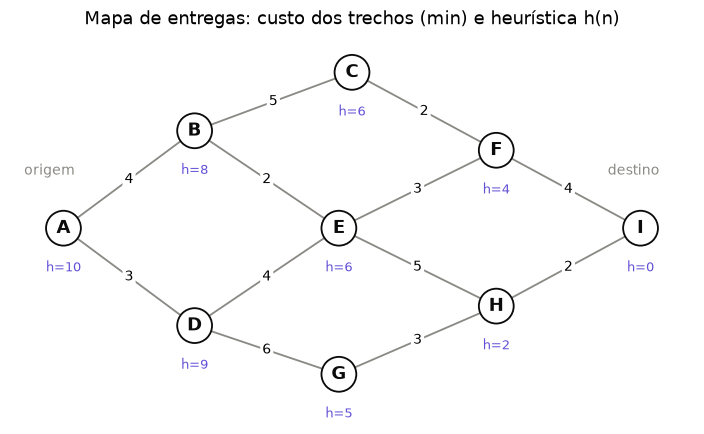

In [3]:
POS = {'A': (0, 1), 'B': (1, 2), 'D': (1, 0), 'C': (2.2, 2.6), 'E': (2.1, 1),
       'G': (2.1, -0.5), 'F': (3.3, 1.8), 'H': (3.3, 0.2), 'I': (4.4, 1)}
G = nx.Graph()
G.add_weighted_edges_from(TRECHOS)

def desenhar(ax, rota=(), cor=AZUL, expandidos=(), titulo='', mostrar_h=True):
    arestas_rota = set(zip(rota, rota[1:])) | set(zip(rota[1:], rota))
    outras = [e for e in G.edges if e not in arestas_rota]
    nx.draw_networkx_edges(G, POS, edgelist=outras, ax=ax, edge_color=CINZA, width=1.2)
    if rota:
        nx.draw_networkx_edges(G, POS, edgelist=list(zip(rota, rota[1:])), ax=ax,
                               edge_color=cor, width=4)
    claro = mcolors.to_hex([0.62 + 0.38 * c for c in mcolors.to_rgb(cor)])  # tom claro e opaco
    cores = [claro if n in expandidos else 'white' for n in G.nodes]
    nx.draw_networkx_nodes(G, POS, ax=ax, node_color=cores, edgecolors=TEXTO,
                           node_size=520, linewidths=1.2)
    nx.draw_networkx_labels(G, POS, ax=ax, font_weight='bold', font_color=TEXTO)
    nx.draw_networkx_edge_labels(G, POS, edge_labels=nx.get_edge_attributes(G, 'weight'),
                                 ax=ax, font_size=9, rotate=False,
                                 bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
    if mostrar_h:
        for n, (x, y) in POS.items():
            ax.text(x, y - 0.33, f'h={H_ENUNCIADO[n]}', ha='center', va='top',
                    fontsize=8.5, color=VIOLETA)
    ax.set_title(titulo)
    ax.set_xlim(-0.4, 4.8); ax.set_ylim(-1.0, 3.0)
    ax.axis('off')

fig, ax = plt.subplots(figsize=(8, 4.6))
desenhar(ax, titulo='Mapa de entregas: custo dos trechos (min) e heurística h(n)')
ax.annotate('origem', POS['A'], xytext=(-0.3, 1.55), fontsize=9, color=CINZA)
ax.annotate('destino', POS['I'], xytext=(4.15, 1.55), fontsize=9, color=CINZA)
fig.savefig(FIG / 'q10_grafo.png')
plt.show()

---
## 2. Formulação do problema

| Componente | Definição |
| --- | --- |
| Estados | A localidade onde o entregador está: S = {A, B, C, D, E, F, G, H, I} |
| Estado inicial | A |
| Ações | `ACOES(s)` = ir para cada vizinho de s no grafo, em ordem alfabética |
| Transição | `RESULTADO(s, ir para x) = x` |
| Teste de objetivo | s = I |
| Custo do caminho | Soma dos minutos dos trechos percorridos; custo do passo `c(s, ir para x, x)` = peso da aresta s–x |

A classe `ProblemaRota` implementa exatamente essa tabela:

In [4]:
P = ProblemaRota()
for s in 'AEI':
    print(f"ACOES({s}) = {P.acoes(s)}  custos = {[P.custo_acao(s, a, P.resultado(s, a)) for a in P.acoes(s)]}"
          f"  objetivo? {P.eh_objetivo(s)}")

ACOES(A) = ['B', 'D']  custos = [4, 3]  objetivo? False
ACOES(E) = ['B', 'D', 'F', 'H']  custos = [2, 4, 3, 5]  objetivo? False
ACOES(I) = ['F', 'H']  custos = [4, 2]  objetivo? True


---
## 3. A heurística dada é admissível? É consistente?

Calculamos o custo ótimo real h*(n) de cada nó até I com Dijkstra a partir de I
(o grafo é não direcionado, então a distância de I até n é a mesma de n até I).
Admissível exige h(n) ≤ h*(n) para todo n. Consistente exige h(n) ≤ c(n, n') + h(n')
para todo par de vizinhos, nos dois sentidos de cada trecho.

In [5]:
h_estrela = dijkstra(GRAFO, 'I')
adm = pd.DataFrame({'h(n)': H_ENUNCIADO, 'h*(n)': h_estrela}).loc[list('ABCDEFGHI')]
adm['h*(n) - h(n)'] = adm['h*(n)'] - adm['h(n)']
adm['admissível'] = adm['h(n)'] <= adm['h*(n)']
display(adm.T)

linhas = []
for u in sorted(GRAFO):
    for v in sorted(GRAFO[u]):
        c = GRAFO[u][v]
        linhas.append({'n': u, "n'": v, 'h(n)': H_ENUNCIADO[u], "c(n,n')": c, "h(n')": H_ENUNCIADO[v],
                       "folga = c + h(n') - h(n)": c + H_ENUNCIADO[v] - H_ENUNCIADO[u]})
cons = pd.DataFrame(linhas)
print('Arestas dirigidas verificadas:', len(cons), '| menor folga:', cons.iloc[:, -1].min())
display(cons[cons.iloc[:, -1] == 0])

v = verificar_heuristica(P, h_enunciado)
print('admissível:', v['admissivel'], '| consistente:', v['consistente'])

,A,B,C,D,E,F,G,H,I
h(n),10,8,6,9,6,4,5,2,0
h*(n),13,9,6,11,7,4,5,2,0
h*(n) - h(n),3,1,0,2,1,0,0,0,0
admissível,True,True,True,True,True,True,True,True,True


Arestas dirigidas verificadas: 24 | menor folga: 0


,n,n',h(n),"c(n,n')",h(n'),folga = c + h(n') - h(n)
4,B,E,8,2,6,0
6,C,F,6,2,4,0
16,F,I,4,4,0,0
18,G,H,5,3,2,0
21,H,I,2,2,0,0


admissível: True | consistente: True


Nenhuma folga é negativa, então h é consistente (e, por consequência, admissível). Cinco arestas
têm folga zero (B→E, C→F, F→I, G→H, H→I): nelas h cai exatamente o custo do trecho. Em C, F, G, H e I a
heurística é exata (h = h*). Onde ela mais erra é em A (13 − 10 = 3) e D (11 − 9 = 2).

Com h consistente, o A* em busca em grafo é ótimo: os valores de f ao longo de qualquer caminho
nunca diminuem, então a primeira vez que um nó sai da fronteira ele já tem o menor g possível e
o conjunto de explorados nunca descarta um caminho melhor.

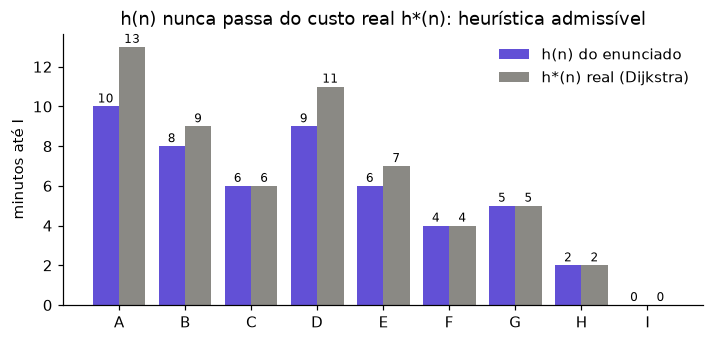

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
x = range(len(adm))
ax.bar([i - 0.2 for i in x], adm['h(n)'], width=0.4, color=VIOLETA, label='h(n) do enunciado')
ax.bar([i + 0.2 for i in x], adm['h*(n)'], width=0.4, color=CINZA, label='h*(n) real (Dijkstra)')
for i, (h, hx) in enumerate(zip(adm['h(n)'], adm['h*(n)'])):
    ax.text(i - 0.2, h + 0.2, h, ha='center', fontsize=8)
    ax.text(i + 0.2, hx + 0.2, hx, ha='center', fontsize=8)
ax.set_xticks(list(x), adm.index)
ax.set_ylabel('minutos até I')
ax.set_title('h(n) nunca passa do custo real h*(n): heurística admissível')
ax.legend(frameon=False)
fig.savefig(FIG / 'q10_heuristica.png')
plt.show()

---
## 4. Convenções que mudam o trace

1. **Busca em grafo**: há um conjunto de explorados. Um filho só entra na fronteira se não estiver
   nem na fronteira nem nos explorados (AIMA, 3ª ed., fig. 3.7).
2. **Ordem dos sucessores**: alfabética.
3. **Teste de objetivo**: BFS testa quando o filho é gerado (AIMA, fig. 3.11). DFS, UCS e A*
   testam quando o nó sai da fronteira. Para UCS e A* isso é obrigatório para garantir otimalidade.
4. **DFS**: os filhos são empilhados em ordem inversa, de forma que o primeiro em ordem alfabética
   seja o próximo a sair.
5. **UCS e A***: se um estado já na fronteira for alcançado com g menor, a entrada é substituída.
6. **Desempate** na fila de prioridade: ordem de inserção (FIFO). Uma entrada substituída conta
   como inserida de novo.

Nas tabelas, `X[g]` é um sucessor gerado com seu custo acumulado; na fronteira, UCS mostra `X(g)`
e A* mostra `X(f)`, na ordem em que sairiam.

---
## 5. Busca não informada

### 5.1 BFS (busca em largura)

In [7]:
r_bfs = bfs(P)
mostrar(tabela_trace(r_bfs))
print(resumo(r_bfs))

| Passo | Retirado | g | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- |
| 1 | A | 0 | B[4], D[3] | B D | A |
| 2 | B | 4 | A[8] explorado, C[9], E[6] | D C E | A, B |
| 3 | D | 3 | A[6] explorado, E[7] já na fronteira, G[9] | C E G | A, B, D |
| 4 | C | 9 | B[14] explorado, F[11] | E G F | A, B, D, C |
| 5 | E | 6 | B[8] explorado, D[10] explorado, F[9] já na fronteira, H[11] | G F H | A, B, D, C, E |
| 6 | G | 9 | D[15] explorado, H[12] já na fronteira | F H | A, B, D, C, E, G |
| 7 | F | 11 | C[13] explorado, E[14] explorado, I[15] objetivo | H I | A, B, D, C, E, G, F |

{'algoritmo': 'BFS', 'rota': 'A → B → C → F → I', 'custo': 15, 'expandidos': 7, 'gerados': 20, 'ordem': 'A B D C E G F'}


Quando I é gerado a partir de F a busca para. A BFS acha o caminho com menos trechos (4), mas
custa 15 minutos: ela ignora os pesos. Testando o objetivo só na expansão, ela teria expandido
também H antes de retirar I, com a mesma rota:

In [8]:
print(resumo(bfs(P, teste_na_geracao=False)))

{'algoritmo': 'BFS', 'rota': 'A → B → C → F → I', 'custo': 15, 'expandidos': 8, 'gerados': 23, 'ordem': 'A B D C E G F H I'}


### 5.2 DFS (busca em profundidade)

In [9]:
r_dfs = dfs(P)
mostrar(tabela_trace(r_dfs))
print(resumo(r_dfs))

| Passo | Retirado | g | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- |
| 1 | A | 0 | B[4], D[3] | B D | A |
| 2 | B | 4 | A[8] explorado, C[9], E[6] | C E D | A, B |
| 3 | C | 9 | B[14] explorado, F[11] | F E D | A, B, C |
| 4 | F | 11 | C[13] explorado, E[14] já na fronteira, I[15] | I E D | A, B, C, F |
| 5 | I | 15 | objetivo, para | E D | A, B, C, F |

{'algoritmo': 'DFS', 'rota': 'A → B → C → F → I', 'custo': 15, 'expandidos': 4, 'gerados': 11, 'ordem': 'A B C F I'}


A DFS desce por A → B → C → F e encontra I logo na primeira descida, expandindo só 4 nós.
A rota também custa 15. Ela chegou ao mesmo caminho da BFS por acaso da ordem alfabética:
nada na DFS olha para custos.

### 5.3 UCS (custo uniforme)

In [10]:
r_ucs = ucs(P)
mostrar(tabela_trace(r_ucs))
print(resumo(r_ucs))

| Passo | Retirado | g | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- |
| 1 | A | 0 | B[4], D[3] | D(3) B(4) | A |
| 2 | D | 3 | A[6] explorado, E[7], G[9] | B(4) E(7) G(9) | A, D |
| 3 | B | 4 | A[8] explorado, C[9], E[6] atualizado (g 7→6) | E(6) G(9) C(9) | A, D, B |
| 4 | E | 6 | B[8] explorado, D[10] explorado, F[9], H[11] | G(9) C(9) F(9) H(11) | A, D, B, E |
| 5 | G | 9 | D[15] explorado, H[12] já na fronteira | C(9) F(9) H(11) | A, D, B, E, G |
| 6 | C | 9 | B[14] explorado, F[11] já na fronteira | F(9) H(11) | A, D, B, E, G, C |
| 7 | F | 9 | C[11] explorado, E[12] explorado, I[13] | H(11) I(13) | A, D, B, E, G, C, F |
| 8 | H | 11 | E[16] explorado, G[14] explorado, I[13] já na fronteira | I(13) | A, D, B, E, G, C, F, H |
| 9 | I | 13 | objetivo, para | ∅ | A, D, B, E, G, C, F, H |

{'algoritmo': 'UCS', 'rota': 'A → B → E → F → I', 'custo': 13, 'expandidos': 8, 'gerados': 23, 'ordem': 'A D B E G C F H I'}


Pontos do trace que merecem atenção:

* No passo 3, E já estava na fronteira com g = 7 (via D) e é reencontrado via B com g = 6; a entrada é substituída.
* No passo 4 três nós empatam com g = 9 (G, C, F). Pelo desempate FIFO sai G, inserido primeiro.
* I é gerado com g = 13 no passo 7, mas só é aceito como solução no passo 9, quando sai da fronteira.
  Nesse meio-tempo H (g = 11) é expandido e tenta I também com 13, o que não melhora nada.

A UCS acha A → B → E → F → I com 13 minutos. Existe outra rota ótima, A → B → E → H → I, também
com 13 minutos; qual das duas aparece depende só do desempate.

---
## 6. Busca informada: A*

In [11]:
r_astar = a_estrela(P, h_enunciado)
mostrar(tabela_trace(r_astar))
print(resumo(r_astar))

| Passo | Retirado | g | h | f | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | A | 0 | 10 | 10 | B[4], D[3] | B(12) D(12) | A |
| 2 | B | 4 | 8 | 12 | A[8] explorado, C[9], E[6] | D(12) E(12) C(15) | A, B |
| 3 | D | 3 | 9 | 12 | A[6] explorado, E[7] já na fronteira, G[9] | E(12) G(14) C(15) | A, B, D |
| 4 | E | 6 | 6 | 12 | B[8] explorado, D[10] explorado, F[9], H[11] | F(13) H(13) G(14) C(15) | A, B, D, E |
| 5 | F | 9 | 4 | 13 | C[11] já na fronteira, E[12] explorado, I[13] | H(13) I(13) G(14) C(15) | A, B, D, E, F |
| 6 | H | 11 | 2 | 13 | E[16] explorado, G[14] já na fronteira, I[13] já na fronteira | I(13) G(14) C(15) | A, B, D, E, F, H |
| 7 | I | 13 | 0 | 13 | objetivo, para | G(14) C(15) | A, B, D, E, F, H |

{'algoritmo': 'A*', 'rota': 'A → B → E → F → I', 'custo': 13, 'expandidos': 6, 'gerados': 19, 'ordem': 'A B D E F H I'}


Os valores de f dos nós retirados nunca diminuem (10, 12, 12, 12, 13, 13, 13), como esperado de
uma heurística consistente. O A* não expande C (f = 15) nem G (f = 14), porque o objetivo sai
com f = 13 antes. Em relação à UCS, economiza C e G: 6 expansões contra 8.

### 6.1 O desempate muda a rota

Com o desempate (f, h, inserção), que favorece o nó mais perto do objetivo:

In [12]:
r_astar_h = a_estrela(P, h_enunciado, desempate_por_h=True)
mostrar(tabela_trace(r_astar_h))
print(resumo(r_astar_h))

| Passo | Retirado | g | h | f | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | A | 0 | 10 | 10 | B[4], D[3] | B(12) D(12) | A |
| 2 | B | 4 | 8 | 12 | A[8] explorado, C[9], E[6] | E(12) D(12) C(15) | A, B |
| 3 | E | 6 | 6 | 12 | B[8] explorado, D[10] já na fronteira, F[9], H[11] | D(12) H(13) F(13) C(15) | A, B, E |
| 4 | D | 3 | 9 | 12 | A[6] explorado, E[7] explorado, G[9] | H(13) F(13) G(14) C(15) | A, B, E, D |
| 5 | H | 11 | 2 | 13 | E[16] explorado, G[14] já na fronteira, I[13] | I(13) F(13) G(14) C(15) | A, B, E, D, H |
| 6 | I | 13 | 0 | 13 | objetivo, para | F(13) G(14) C(15) | A, B, E, D, H |

{'algoritmo': 'A*', 'rota': 'A → B → E → H → I', 'custo': 13, 'expandidos': 5, 'gerados': 16, 'ordem': 'A B E D H I'}


Agora o A* encontra a outra rota ótima, A → B → E → H → I, com 5 expansões. O custo continua 13;
a otimalidade não depende do desempate, só a escolha entre rotas de mesmo custo e a quantidade de
nós expandidos quando há empates em f.

### 6.2 A* com h = 0 é a UCS

In [13]:
r_h0 = a_estrela(P, h_nula)
print('mesma ordem de expansão que a UCS:', r_h0.ordem_expansao == r_ucs.ordem_expansao)
print(resumo(r_h0))

mesma ordem de expansão que a UCS: True
{'algoritmo': 'A*', 'rota': 'A → B → E → F → I', 'custo': 13, 'expandidos': 8, 'gerados': 23, 'ordem': 'A D B E G C F H I'}


---
## 7. Comparação

In [14]:
resultados = {'BFS': r_bfs, 'DFS': r_dfs, 'UCS': r_ucs, 'A*': r_astar,
              'A* (desempate por h)': r_astar_h}
comp = pd.DataFrame([{**resumo(r), 'algoritmo': nome} for nome, r in resultados.items()]).set_index('algoritmo')
comp['completo?'] = ['sim', 'sim (grafo finito)', 'sim', 'sim', 'sim']
comp['ótimo?'] = ['não (só com custos iguais)', 'não', 'sim', 'sim (h consistente)', 'sim (h consistente)']
display(comp)

,rota,custo,expandidos,gerados,ordem,completo?,ótimo?
algoritmo,,,,,,,
BFS,A → B → C → F → I,15,7,20,A B D C E G F,sim,não (só com custos iguais)
DFS,A → B → C → F → I,15,4,11,A B C F I,sim (grafo finito),não
UCS,A → B → E → F → I,13,8,23,A D B E G C F H I,sim,sim
A*,A → B → E → F → I,13,6,19,A B D E F H I,sim,sim (h consistente)
A* (desempate por h),A → B → E → H → I,13,5,16,A B E D H I,sim,sim (h consistente)


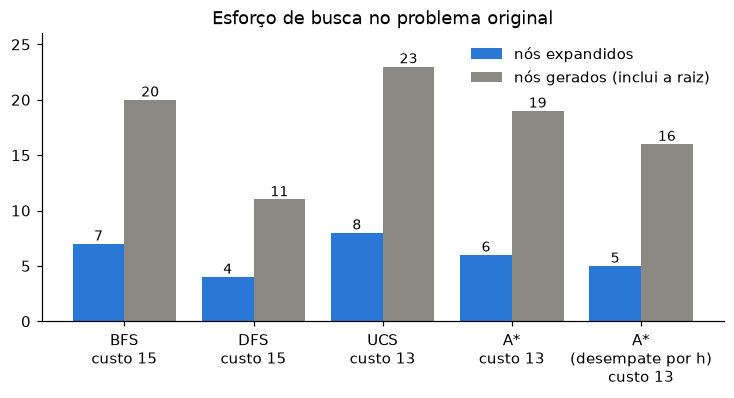

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.4))
nomes = list(resultados)
exp = [resultados[n].expandidos for n in nomes]
ger = [resultados[n].gerados for n in nomes]
x = range(len(nomes))
ax.bar([i - 0.2 for i in x], exp, width=0.4, color=AZUL, label='nós expandidos')
ax.bar([i + 0.2 for i in x], ger, width=0.4, color=CINZA, label='nós gerados (inclui a raiz)')
for i in x:
    ax.text(i - 0.2, exp[i] + 0.3, exp[i], ha='center', fontsize=9)
    ax.text(i + 0.2, ger[i] + 0.3, ger[i], ha='center', fontsize=9)
rotulos = [n.replace(' (', '\n(') + '\ncusto ' + str(resultados[n].custo) for n in nomes]
ax.set_xticks(list(x), rotulos)
ax.set_ylim(0, max(ger) + 3)
ax.set_title('Esforço de busca no problema original')
ax.legend(frameon=False, loc='upper right')
fig.savefig(FIG / 'q10_expansoes.png')
plt.show()

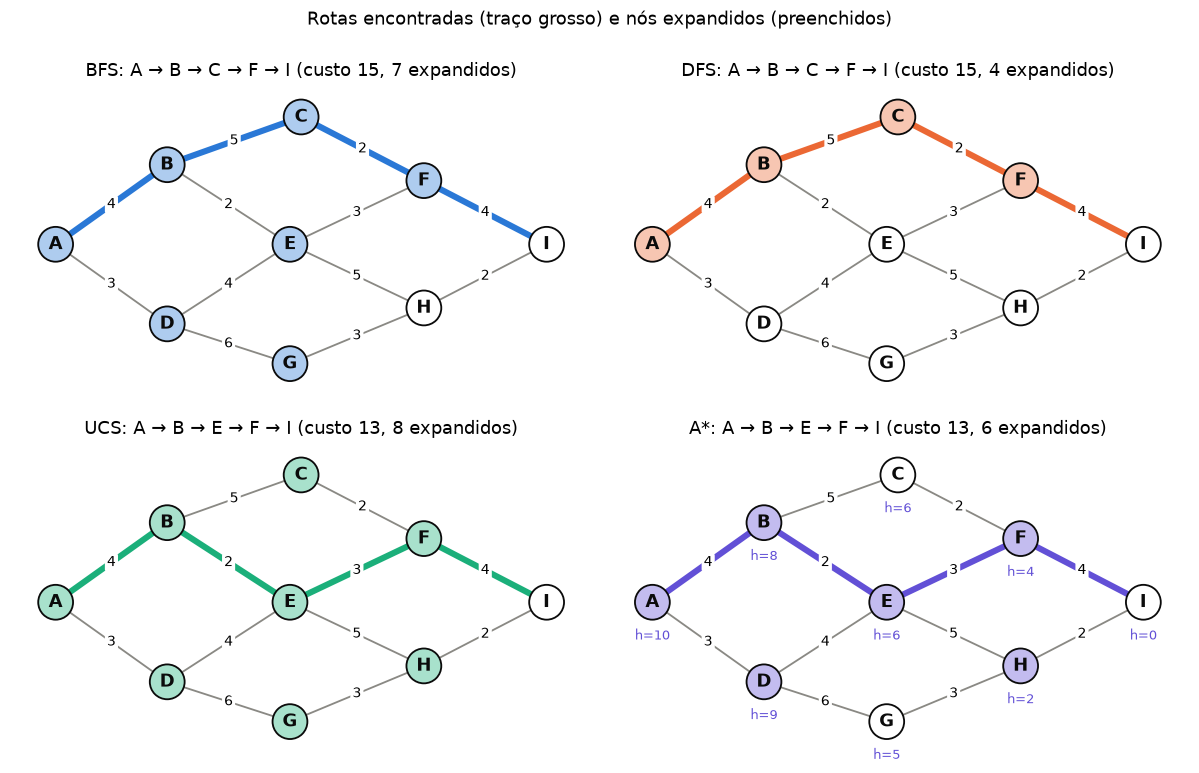

In [16]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for ax, (nome, r, cor) in zip(axs.flat, [('BFS', r_bfs, AZUL), ('DFS', r_dfs, LARANJA),
                                         ('UCS', r_ucs, AQUA), ('A*', r_astar, VIOLETA)]):
    expandidos = r.ordem_expansao[:r.expandidos]
    desenhar(ax, r.rota, cor, expandidos,
             f"{nome}: {' → '.join(r.rota)} (custo {r.custo}, {r.expandidos} expandidos)", mostrar_h=(nome == 'A*'))
fig.suptitle('Rotas encontradas (traço grosso) e nós expandidos (preenchidos)', y=1.0)
fig.tight_layout()
fig.savefig(FIG / 'q10_rotas.png')
plt.show()

DFS e BFS terminam com 15 minutos, 2 a mais que o ótimo. A DFS foi a que menos expandiu (4), mas
porque teve sorte com a ordem alfabética: com outra ordem de vizinhos ela poderia descer por
A → D → G → H → I (14) ou vagar bem mais. A UCS e o A* garantem os 13 minutos, e o A* chega lá
expandindo 6 nós contra 8 da UCS.

---
## 8. Variante: passar obrigatoriamente por D e F antes de I

Só a localidade não basta como estado: estar em E tendo passado por D é diferente de estar em E
sem ter passado. O estado passa a ser **(nó, visitouD, visitouF)**.

| Componente | Definição |
| --- | --- |
| Estados | (n, d, f) com n ∈ {A, …, I} e d, f ∈ {0, 1}: 9 × 4 = 36 estados, 32 alcançáveis a partir de A |
| Estado inicial | (A, 0, 0) |
| Ações | Ir para cada vizinho de n (as mesmas do problema original) |
| Transição | RESULTADO((n, d, f), ir para x) = (x, d ∨ [x = D], f ∨ [x = F]) |
| Teste de objetivo | n = I, d = 1 e f = 1 |
| Custo do passo | Peso da aresta n–x (não muda) |

Passar por I antes de cumprir as paradas é permitido (o estado não é objetivo, a busca segue).
Não altera o ótimo neste mapa.

### 8.1 Heurística para o espaço aumentado

A h do enunciado aplicada só à localidade, h₁(n, d, f) = h(n), continua admissível e consistente:
toda rota válida no espaço aumentado é também uma rota de n até I no grafo, logo custa pelo menos
h*(n) ≥ h(n). Mas ela não enxerga as paradas pendentes.

Proposta:

$$h_{DF}(n, d, f) = \max\Big(h(n),\ [d=0]\,\big(\delta(n, D) + h(D)\big),\ [f=0]\,\big(\delta(n, F) + h(F)\big)\Big)$$

onde δ(n, m) é a menor distância no grafo (Dijkstra a partir de D e de F, feito uma vez). Os termos
de paradas já visitadas são omitidos.

*Admissibilidade*: se a parada m está pendente, qualquer rota válida a partir de n passa por m e
depois chega a I. O trecho até m custa ≥ δ(n, m) e o trecho de m até I custa ≥ h*(m) ≥ h(m).
Cada termo é um limite inferior, e o máximo de limites inferiores também é.

*Consistência*: para uma transição s → s' com custo c, h(n) ≤ c + h(n') vale porque h é consistente.
Se m continua pendente em s', δ(n, m) ≤ c + δ(n', m) pela desigualdade triangular. Se s' acabou de
visitar m (n' = m), o termo de s vale δ(n, m) + h(m) ≤ c + h(m) ≤ c + h_DF(s'). Em todos os casos
cada termo de h_DF(s) é ≤ c + h_DF(s').

Conferência numérica nos 32 estados alcançáveis:

In [17]:
PDF = ProblemaRotaDF()
h_df = criar_h_paradas()
for nome, h in [('h1 = h(n)', h_enunciado), ('h_DF', h_df)]:
    v = verificar_heuristica(PDF, h)
    folga_media = sum(hx - hs for _, hs, hx in v['tabela']) / len(v['tabela'])
    print(f"{nome:10s} admissível={v['admissivel']}  consistente={v['consistente']}  "
          f"erro médio h* - h = {folga_media:.2f}")

v = verificar_heuristica(PDF, h_df)
tab = pd.DataFrame([(PDF.rotulo(s), h_enunciado(s), hs, hx) for s, hs, hx in v['tabela']],
                   columns=['estado', 'h1', 'h_DF', 'h*']).set_index('estado').sort_index()
display(tab)

h1 = h(n)  admissível=True  consistente=True  erro médio h* - h = 7.12
h_DF       admissível=True  consistente=True  erro médio h* - h = 1.12


,h1,h_DF,h*
estado,,,
"(A,0,0)",10,13,14
"(A,0,1)",10,12,14
"(A,1,0)",10,13,13
"(A,1,1)",10,10,13
"(B,0,0)",8,15,17
"(B,0,1)",8,15,17
"(B,1,0)",8,9,9
"(B,1,1)",8,8,9
"(C,0,0)",6,18,20


### 8.2 UCS no espaço aumentado

In [18]:
r_ucs_df = ucs(PDF)
mostrar(tabela_trace(r_ucs_df))
print(resumo(r_ucs_df))

| Passo | Retirado | g | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- |
| 1 | (A,0,0) | 0 | (B,0,0)[4], (D,1,0)[3] | (D,1,0)(3) (B,0,0)(4) | (A,0,0) |
| 2 | (D,1,0) | 3 | (A,1,0)[6], (E,1,0)[7], (G,1,0)[9] | (B,0,0)(4) (A,1,0)(6) (E,1,0)(7) (G,1,0)(9) | (A,0,0), (D,1,0) |
| 3 | (B,0,0) | 4 | (A,0,0)[8] explorado, (C,0,0)[9], (E,0,0)[6] | (A,1,0)(6) (E,0,0)(6) (E,1,0)(7) (G,1,0)(9) (C,0,0)(9) | (A,0,0), (D,1,0), (B,0,0) |
| 4 | (A,1,0) | 6 | (B,1,0)[10], (D,1,0)[9] explorado | (E,0,0)(6) (E,1,0)(7) (G,1,0)(9) (C,0,0)(9) (B,1,0)(10) | (A,0,0), (D,1,0), (B,0,0), (A,1,0) |
| 5 | (E,0,0) | 6 | (B,0,0)[8] explorado, (D,1,0)[10] explorado, (F,0,1)[9], (H,0,0)[11] | (E,1,0)(7) (G,1,0)(9) (C,0,0)(9) (F,0,1)(9) (B,1,0)(10) (H,0,0)(11) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0) |
| 6 | (E,1,0) | 7 | (B,1,0)[9] atualizado (g 10→9), (D,1,0)[11] explorado, (F,1,1)[10], (H,1,0)[12] | (G,1,0)(9) (C,0,0)(9) (F,0,1)(9) (B,1,0)(9) (F,1,1)(10) (H,0,0)(11) (H,1,0)(12) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0) |
| 7 | (G,1,0) | 9 | (D,1,0)[15] explorado, (H,1,0)[12] já na fronteira | (C,0,0)(9) (F,0,1)(9) (B,1,0)(9) (F,1,1)(10) (H,0,0)(11) (H,1,0)(12) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0) |
| 8 | (C,0,0) | 9 | (B,0,0)[14] explorado, (F,0,1)[11] já na fronteira | (F,0,1)(9) (B,1,0)(9) (F,1,1)(10) (H,0,0)(11) (H,1,0)(12) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0) |
| 9 | (F,0,1) | 9 | (C,0,1)[11], (E,0,1)[12], (I,0,1)[13] | (B,1,0)(9) (F,1,1)(10) (H,0,0)(11) (C,0,1)(11) (H,1,0)(12) (E,0,1)(12) (I,0,1)(13) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1) |
| 10 | (B,1,0) | 9 | (A,1,0)[13] explorado, (C,1,0)[14], (E,1,0)[11] explorado | (F,1,1)(10) (H,0,0)(11) (C,0,1)(11) (H,1,0)(12) (E,0,1)(12) (I,0,1)(13) (C,1,0)(14) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0) |
| 11 | (F,1,1) | 10 | (C,1,1)[12], (E,1,1)[13], (I,1,1)[14] | (H,0,0)(11) (C,0,1)(11) (H,1,0)(12) (E,0,1)(12) (C,1,1)(12) (I,0,1)(13) (E,1,1)(13) (C,1,0)(14) (I,1,1)(14) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1) |
| 12 | (H,0,0) | 11 | (E,0,0)[16] explorado, (G,0,0)[14], (I,0,0)[13] | (C,0,1)(11) (H,1,0)(12) (E,0,1)(12) (C,1,1)(12) (I,0,1)(13) (E,1,1)(13) (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0) |
| 13 | (C,0,1) | 11 | (B,0,1)[16], (F,0,1)[13] explorado | (H,1,0)(12) (E,0,1)(12) (C,1,1)(12) (I,0,1)(13) (E,1,1)(13) (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (B,0,1)(16) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1) |
| 14 | (H,1,0) | 12 | (E,1,0)[17] explorado, (G,1,0)[15] explorado, (I,1,0)[14] | (E,0,1)(12) (C,1,1)(12) (I,0,1)(13) (E,1,1)(13) (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(16) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0) |
| 15 | (E,0,1) | 12 | (B,0,1)[14] atualizado (g 16→14), (D,1,1)[16], (F,0,1)[15] explorado, (H,0,1)[17] | (C,1,1)(12) (I,0,1)(13) (E,1,1)(13) (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (D,1,1)(16) (H,0,1)(17) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1) |
| 16 | (C,1,1) | 12 | (B,1,1)[17], (F,1,1)[14] explorado | (I,0,1)(13) (E,1,1)(13) (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (D,1,1)(16) (H,0,1)(17) (B,1,1)(17) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1), (C,1,1) |
| 17 | (I,0,1) | 13 | (F,0,1)[17] explorado, (H,0,1)[15] atualizado (g 17→15) | (E,1,1)(13) (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (H,0,1)(15) (D,1,1)(16) (B,1,1)(17) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1), (C,1,1), (I,0,1) |
| 18 | (E,1,1) | 13 | (B,1,1)[15] atualizado (g 17→15), (D,1,1)[17] já na fronteira, (F,1,1)[16] explorado, (H,1,1)[18] | (I,0,0)(13) (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (H,0,1)(15) (B,1,1)(15) (D,1,1)(16) (H,1,1)(18) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1), (C,1,1), (I,0,1), (E,1,1) |
| 19 | (I,0,0) | 13 | (F,0,1)[17] explorado, (H,0,0)[15] explorado | (C,1,0)(14) (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (H,0,1)(15) (B,1,1)(15) (D,1,1)(16) (H,1,1)(18) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1), (C,1,1), (I,0,1), (E,1,1), (I,0,0) |
| 20 | (C,1,0) | 14 | (B,1,0)[19] explorado, (F,1,1)[16] explorado | (I,1,1)(14) (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (H,0,1)(15) (B,1,1)(15) (D,1,1)(16) (H,1,1)(18) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1), (C,1,1), (I,0,1), (E,1,1), (I,0,0), (C,1,0) |
| 21 | (I,1,1) | 14 | objetivo, para | (G,0,0)(14) (I,1,0)(14) (B,0,1)(14) (H,0,1)(15) (B,1,1)(15) (D,1,1)(16) (H,1,1)(18) | (A,0,0), (D,1,0), (B,0,0), (A,1,0), (E,0,0), (E,1,0), (G,1,0), (C,0,0), (F,0,1), (B,1,0), (F,1,1), (H,0,0), (C,0,1), (H,1,0), (E,0,1), (C,1,1), (I,0,1), (E,1,1), (I,0,0), (C,1,0) |

{'algoritmo': 'UCS', 'rota': '(A,0,0) → (D,1,0) → (E,1,0) → (F,1,1) → (I,1,1)', 'custo': 14, 'expandidos': 20, 'gerados': 56, 'ordem': '(A,0,0) (D,1,0) (B,0,0) (A,1,0) (E,0,0) (E,1,0) (G,1,0) (C,0,0) (F,0,1) (B,1,0) (F,1,1) (H,0,0) (C,0,1) (H,1,0) (E,0,1) (C,1,1) (I,0,1) (E,1,1) (I,0,0) (C,1,0) (I,1,1)'}


### 8.3 A* com h_DF

In [19]:
r_astar_df = a_estrela(PDF, h_df)
mostrar(tabela_trace(r_astar_df))
print(resumo(r_astar_df))

| Passo | Retirado | g | h | f | Sucessores gerados | Fronteira depois | Explorados |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | (A,0,0) | 0 | 13 | 13 | (B,0,0)[4], (D,1,0)[3] | (D,1,0)(14) (B,0,0)(19) | (A,0,0) |
| 2 | (D,1,0) | 3 | 11 | 14 | (A,1,0)[6], (E,1,0)[7], (G,1,0)[9] | (E,1,0)(14) (B,0,0)(19) (A,1,0)(19) (G,1,0)(22) | (A,0,0), (D,1,0) |
| 3 | (E,1,0) | 7 | 7 | 14 | (B,1,0)[9], (D,1,0)[11] explorado, (F,1,1)[10], (H,1,0)[12] | (F,1,1)(14) (B,1,0)(18) (B,0,0)(19) (A,1,0)(19) (G,1,0)(22) (H,1,0)(22) | (A,0,0), (D,1,0), (E,1,0) |
| 4 | (F,1,1) | 10 | 4 | 14 | (C,1,1)[12], (E,1,1)[13], (I,1,1)[14] | (I,1,1)(14) (B,1,0)(18) (C,1,1)(18) (B,0,0)(19) (A,1,0)(19) (E,1,1)(19) (G,1,0)(22) (H,1,0)(22) | (A,0,0), (D,1,0), (E,1,0), (F,1,1) |
| 5 | (I,1,1) | 14 | 0 | 14 | objetivo, para | (B,1,0)(18) (C,1,1)(18) (B,0,0)(19) (A,1,0)(19) (E,1,1)(19) (G,1,0)(22) (H,1,0)(22) | (A,0,0), (D,1,0), (E,1,0), (F,1,1) |

{'algoritmo': 'A*', 'rota': '(A,0,0) → (D,1,0) → (E,1,0) → (F,1,1) → (I,1,1)', 'custo': 14, 'expandidos': 4, 'gerados': 13, 'ordem': '(A,0,0) (D,1,0) (E,1,0) (F,1,1) (I,1,1)'}


Com h_DF o A* vai direto: h_DF(A, 0, 0) = max(10, 3 + 9, 9 + 4) = 13 e, a partir de (D, 1, 0),
a heurística coincide com o custo real, então só os nós da rota ótima são expandidos.

### 8.4 Comparação na variante

In [20]:
r_astar_h1 = a_estrela(PDF, h_enunciado)
var = {'BFS': bfs(PDF), 'DFS': dfs(PDF), 'UCS': r_ucs_df, 'A* com h1': r_astar_h1, 'A* com h_DF': r_astar_df}
comp_df = pd.DataFrame([{**resumo(r), 'algoritmo': n} for n, r in var.items()]).set_index('algoritmo')
display(comp_df[['rota', 'custo', 'expandidos', 'gerados']])

,rota,custo,expandidos,gerados
algoritmo,,,,
BFS,"(A,0,0) → (D,1,0) → (E,1,0) → (F,1,1) → (I,1,1)",14,12,35
DFS,"(A,0,0) → (B,0,0) → (C,0,0) → (F,0,1) → (C,0,1) → (B,0,1) → (A,0,1) → (D,1,1) → (A,1,1) → (B,1,1) → (C,1,1) → (F,1,1) → (I,1,1)",43,12,31
UCS,"(A,0,0) → (D,1,0) → (E,1,0) → (F,1,1) → (I,1,1)",14,20,56
A* com h1,"(A,0,0) → (D,1,0) → (E,1,0) → (F,1,1) → (I,1,1)",14,12,35
A* com h_DF,"(A,0,0) → (D,1,0) → (E,1,0) → (F,1,1) → (I,1,1)",14,4,13


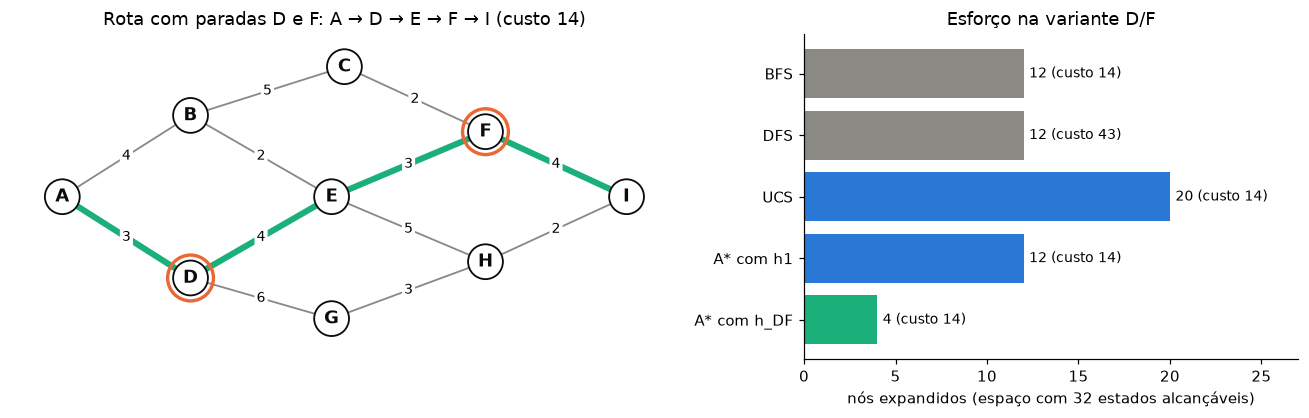

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={'width_ratios': [1.35, 1]})
rota_df = [s[0] for s in r_astar_df.rota]
desenhar(ax1, rota_df, AQUA, titulo=f"Rota com paradas D e F: {' → '.join(rota_df)} (custo {r_astar_df.custo})",
         mostrar_h=False)
for n in 'DF':
    ax1.scatter(*POS[n], s=900, facecolors='none', edgecolors=LARANJA, linewidths=2.2, zorder=5)
nomes = list(var)
exp = [var[n].expandidos for n in nomes]
ax2.barh(nomes[::-1], exp[::-1], color=[CINZA, CINZA, AZUL, AZUL, AQUA][::-1])
for i, (n, e) in enumerate(zip(nomes[::-1], exp[::-1])):
    ax2.text(e + 0.3, i, f'{e} (custo {var[n].custo})', va='center', fontsize=9)
ax2.set_xlabel('nós expandidos (espaço com 32 estados alcançáveis)')
ax2.set_xlim(0, max(exp) + 7)
ax2.set_title('Esforço na variante D/F')
fig.tight_layout()
fig.savefig(FIG / 'q10_variante_df.png')
plt.show()

A rota de menor custo com as duas paradas é **A → D → E → F → I, com 14 minutos**, só um minuto a
mais que o ótimo sem restrição. UCS, A* com h₁ e A* com h_DF chegam a ela; o que muda é o esforço:
20, 12 e 4 expansões. A BFS também acerta aqui, mas por coincidência (a rota ótima é uma das que têm
menos trechos). A DFS mostra o risco de ignorar custos: anda por 12 trechos e gasta 43 minutos,
porque visita F, volta até A, desce para D e só então refaz o caminho até I.